# IJC309 Building AI Applications - Scenario 1
# News Classification with Transformer Fine-Tuning


**Module:** IJC309 Building AI Applications  
**Assignment:** Component 1 - AI Application Development



## Table of Contents

1. [Environment Setup](#1-environment-setup)
2. [Data Loading and Exploration](#2-data-loading-and-exploration)
3. [Data Preprocessing](#3-data-preprocessing)
4. [Model Architecture](#4-model-architecture)
5. [Training Configuration](#5-training-configuration)
6. [Model Training](#6-model-training)
7. [Evaluation and Metrics](#7-evaluation-and-metrics)
8. [Interactive Demo](#8-interactive-demo)



# **1. Environment Setup**

In [1]:
# Install required packages
!pip install transformers datasets accelerate evaluate scikit-learn peft seaborn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00


In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

#Hugging Face libraries
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    pipeline
)
import evaluate

# Scikit-learn for metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
) #or  f1_score, precision_score, recall_score
from peft import LoraConfig, get_peft_model, TaskType, PeftModel, PeftConfig
# PyTorch
import torch

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


In [3]:
# setting random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **2. Data Loading and Exploration**


In [5]:
# Loading the AG News dataset + demonstrating the total number of samples

dataset = load_dataset("wangrongsheng/ag_news")

print(f"\nThe dataset structure:")
print(dataset)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]


The dataset structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [6]:
train_data = dataset['train']
test_data = dataset['test']
#extracting class names directly from dataset features
labels = dataset["train"].features["label"].names

#class_names dictionary
class_names = {id: name for id, name in enumerate(labels)}


In [7]:
#Printing overview
print(f"\nDataset Overview:")
print(f"Total training samples: {len(train_data):,}")
print(f"Total test samples: {len(test_data):,}")
print(f"Total samples: {len(train_data) + len(test_data):,}")
print(f"\nNumber of classes: {len(class_names)}")

print(f"\nClass Names and Labels:")
for label, name in class_names.items():
    print(f"  Label {label}: {name}")

#Explore dataset samples
print("\n\nSAMPLE NEWS ARTICLES")

for i in range(3):
    sample = dataset['train'][i]
    print(f"\n  Sample {i+1}:")
    print(f"Category: {labels[sample['label']]}")
    print(f"Text: {sample['text'][:210]}...")


Dataset Overview:
Total training samples: 120,000
Total test samples: 7,600
Total samples: 127,600

Number of classes: 4

Class Names and Labels:
  Label 0: World
  Label 1: Sports
  Label 2: Business
  Label 3: Sci/Tech


SAMPLE NEWS ARTICLES

  Sample 1:
Category: Business
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....

  Sample 2:
Category: Business
Text: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, ha...

  Sample 3:
Category: Business
Text: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth o...


In [8]:
# Examining distribution across categories
# Counting samples per class
train_distribution = Counter(train_data['label'])
test_distribution = Counter(test_data['label'])

# distribution dataframe
df = pd.DataFrame({
    'Class': [class_names[i] for i in range(4)],
    'Label': list(range(4)),
    'Training Samples': [train_distribution.get(i, 0) for i in range(4)],
    'Test Samples': [test_distribution.get(i, 0) for i in range(4)]})

df['Training %'] = (df['Training Samples'] / df['Training Samples'].sum() * 100).round(2)
df['Test %'] = (df['Test Samples'] /df['Test Samples'].sum() * 100).round(2)

print("Class distribution table:")
print("\n" + df.to_string(index=False))

Class distribution table:

   Class  Label  Training Samples  Test Samples  Training %  Test %
   World      0             30000          1900        25.0    25.0
  Sports      1             30000          1900        25.0    25.0
Business      2             30000          1900        25.0    25.0
Sci/Tech      3             30000          1900        25.0    25.0


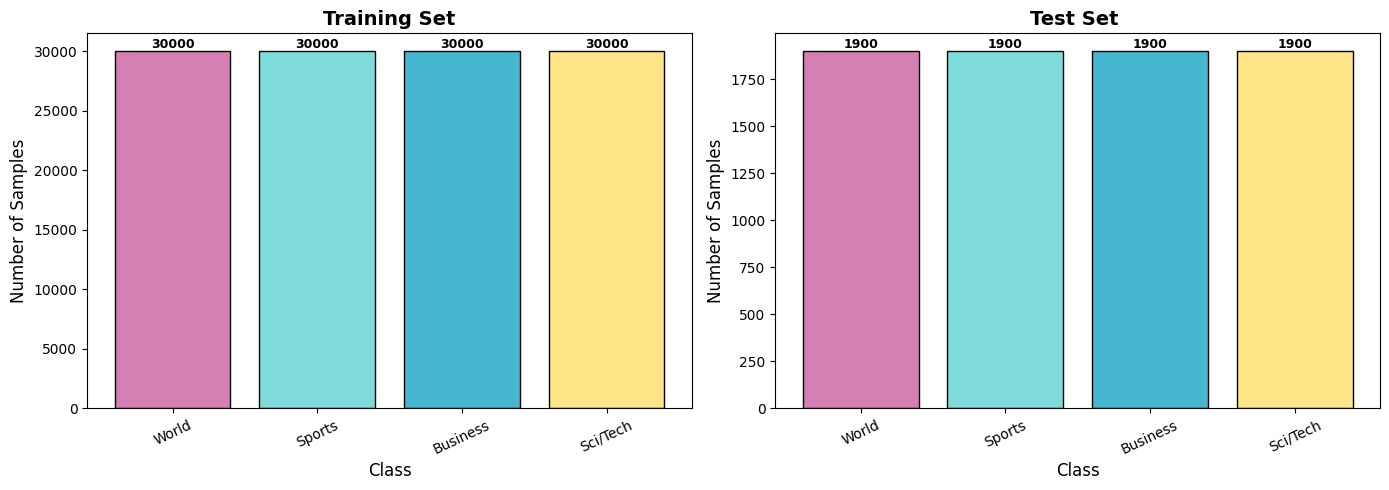

In [9]:
# Visualize distribution: bar chart of classes
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

class_colors = [
    "#D67FB3",
    "#7FDBDA",
    "#45B7D1",
    "#FFE587"  ]


#training set
ax[0].bar(df['Class'], df['Training Samples'], color=class_colors, edgecolor='black')
ax[0].set_title('Training Set', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Class', fontsize=12)
ax[0].set_ylabel('Number of Samples', fontsize=12)
ax[0].tick_params(axis='x', rotation=25)
for i, val in enumerate(df['Training Samples']):
    ax[0].text(i, val + 0, str(val), ha='center', va='bottom', fontweight='bold', fontsize=9)


# Test set distribution
ax[1].bar(df['Class'], df['Test Samples'], color=class_colors,edgecolor='black')
ax[1].set_title('Test Set ', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Class', fontsize=12)
ax[1].set_ylabel('Number of Samples', fontsize=12)
ax[1].tick_params(axis='x', rotation= 25)

for i, val in enumerate(df['Test Samples']):
    ax[1].text(i, val + 0, str(val), ha='center', va='bottom', fontweight='bold', fontsize=9 )

plt.tight_layout()
plt.show()


TEXT LENGTH ANALYSIS

Text Length Descriptive Statistics: 


Statistic  Train   Test
     Mean  37.85  37.72
   Median  37.00  37.00
  Std Dev  10.09  10.13
      Min   8.00  11.00
      Max 177.00 137.00
      25%  32.00  32.00
      75%  43.00  43.00



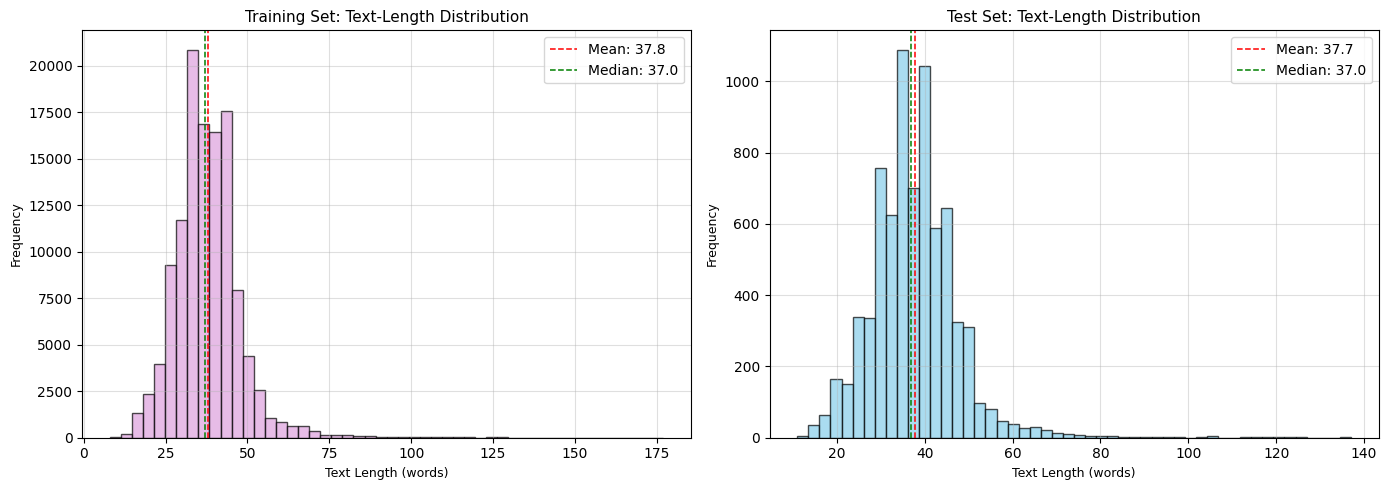

In [10]:
#Text Length analysis

print("\nTEXT LENGTH ANALYSIS")

train_lengths = [len(text.split()) for text in train_data['text']]
test_lengths = [len(text.split()) for text in test_data['text']]


# stats dictionary
def get_stats(values):
    return {
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Std Dev": np.std(values),
        "Min": np.min(values),
        "Max": np.max(values),
        "25%": np.percentile(values, 25),
        "75%": np.percentile(values, 75)}

trainstat = get_stats(train_lengths)
teststat  = get_stats(test_lengths)

# turn into table
stat2df = pd.DataFrame({
    "Statistic": trainstat.keys(),
    "Train": [f"{v:.2f}" for v in trainstat.values()],
    "Test": [f"{v:.2f}" for v in teststat.values()]})

print("\nText Length Descriptive Statistics: ")
print("\n\n" +stat2df.to_string(index=False))
print( )


# Visualize text length distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram for training set
ax[0].hist(train_lengths, bins=50, color='plum', alpha=0.7, edgecolor='black')
ax[0].axvline(trainstat['Mean'], color='red', linestyle='--', linewidth= 1.1, label=f"Mean: {trainstat['Mean']:.1f}")
ax[0].axvline(trainstat['Median'], color='green', linestyle='--', linewidth=1.1, label=f"Median: {trainstat['Median']:.1f}")
ax[0].set_title('Training Set: Text-Length Distribution', fontsize=11)
ax[0].set_xlabel('Text Length (words)', fontsize=9)
ax[0].set_ylabel('Frequency', fontsize=9)
ax[0].legend()
ax[0].grid(True, alpha=0.4)

# same for test set
ax[1].hist(test_lengths, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
ax[1].axvline(teststat['Mean'], color='red', linestyle='--', linewidth=1.1, label=f"Mean: {teststat['Mean']:.1f}")
ax[1].axvline(teststat['Median'], color='green', linestyle='--', linewidth=1.1, label=f"Median: {teststat['Median']:.1f}")
ax[1].set_title('Test Set: Text-Length Distribution', fontsize=11)
ax[1].set_xlabel('Text Length (words)', fontsize=9)
ax[1].set_ylabel('Frequency', fontsize=9)
ax[1].legend()
ax[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

# **3. Data Preprocessing**

In [11]:

from sklearn.model_selection import train_test_split

# sample sizes recommended for the limits of Colab
TRAIN_SUBSET = 1000
TEST_SUBSET = 200

# Stratified sampling (train and test)
train_idx = train_test_split(
    np.arange(len(dataset["train"])),
    test_size=TRAIN_SUBSET,
    stratify=dataset["train"]["label"],
    random_state=SEED)[1]
test_idx = train_test_split(
    np.arange(len(dataset["test"])),
    test_size=TEST_SUBSET,
    stratify=dataset["test"]["label"],
    random_state=SEED
)[1]

train_sampled = dataset["train"].select(train_idx)
test_sampled = dataset["test"].select(test_idx)

# Train/Validation Split (80/20)

train_val = train_sampled.train_test_split(
    test_size=0.2,
    seed=SEED, stratify_by_column="label")

train_set = train_val["train"]
val_set= train_val["test"]



#visualizing the class ditribution - table
traindist = Counter(train_set["label"])
valdist = Counter(val_set["label"])
testdist = Counter(test_sampled["label"])

distr_df = pd.DataFrame({
    "Class": [class_names[i] for i in range(4)],
    "Label": list(range(4)),
    "Train Samples": [traindist.get(i, 0) for i in range(4)],
    "Validation Samples": [valdist.get(i, 0) for i in range(4)],
    "Test Samples": [testdist.get(i, 0) for i in range(4)]
})

distr_df["Train %"] = (distr_df["Train Samples"] / distr_df["Train Samples"].sum() * 100).round(2)
distr_df["Val %"] = (distr_df["Validation Samples"] / distr_df["Validation Samples"].sum() * 100).round(2)
distr_df["Test %"] = (distr_df["Test Samples"] / distr_df["Test Samples"].sum() * 100).round(2)

print("\nDATASET SUBSAMPLING")
print("\nSampling strategy:")
print(f"Training subset:{TRAIN_SUBSET}")
print(f"Test subset:{TEST_SUBSET}")
print("Method: stratified random sampling\n")
print("\nThe final splits:")
print("Train:",len(train_set))
print("Val:",len(val_set))

print("Test:",len(test_sampled))
print("\nClass Distribution Across Splits:\n")
print(distr_df.to_string(index=False))




DATASET SUBSAMPLING

Sampling strategy:
Training subset:1000
Test subset:200
Method: stratified random sampling


The final splits:
Train: 800
Val: 200
Test: 200

Class Distribution Across Splits:

   Class  Label  Train Samples  Validation Samples  Test Samples  Train %  Val %  Test %
   World      0            200                  50            50     25.0   25.0    25.0
  Sports      1            200                  50            50     25.0   25.0    25.0
Business      2            200                  50            50     25.0   25.0    25.0
Sci/Tech      3            200                  50            50     25.0   25.0    25.0


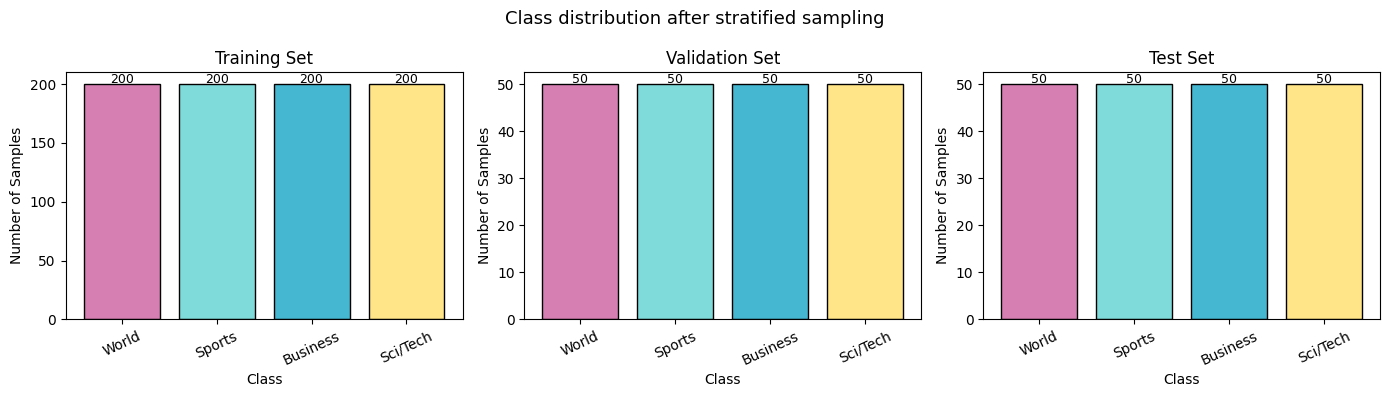

In [12]:
# re-visualise class distribution across splits to check balance - bar charts
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
class_colors = ["#D67FB3", "#7FDBDA", "#45B7D1", "#FFE587"]

#train
ax[0].bar(distr_df["Class"], distr_df["Train Samples"], color=class_colors, edgecolor="black")
ax[0].set_title("Training Set")
ax[0].set_xlabel("Class")
ax[0].set_ylabel("Number of Samples")
ax[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(distr_df["Train Samples"]):
    ax[0].text(i, v-2, str(v), ha="center", va="bottom", fontsize=9)

# val
ax[1].bar(distr_df["Class"], distr_df["Validation Samples"], color=class_colors, edgecolor="black")
ax[1].set_title("Validation Set")
ax[1].set_xlabel("Class")
ax[1].set_ylabel("Number of Samples")
ax[1].tick_params(axis="x", rotation=25)
for i, v in enumerate(distr_df["Validation Samples"]):
    ax[1].text(i, v-0.5, str(v), ha="center", va="bottom", fontsize=9)

#test
ax[2].bar(distr_df["Class"], distr_df["Test Samples"], color=class_colors, edgecolor="black")
ax[2].set_title("Test Set")
ax[2].set_xlabel("Class")
ax[2].set_ylabel("Number of Samples")
ax[2].tick_params(axis="x", rotation=25)
for i, v in enumerate(distr_df["Test Samples"]):
    ax[2].text(i, v-0.5, str(v), ha="center", va="bottom", fontsize=9)



plt.suptitle("Class distribution after stratified sampling", fontsize=13)
plt.tight_layout()
plt.show()


**Tokenisation**

In [13]:

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

#tokenising without truncation to measure true lengths
token_lengths = [
    len(tokenizer(text, truncation=False)["input_ids"])
    for text in train_data["text"]
]

MAX_LEN = 128

#truncated samples
num_truncated = sum(length > MAX_LEN for length in token_lengths)
total_samples = len(token_lengths)

truncation_rate = (num_truncated / total_samples) * 100

print(f"Samples exceeding {MAX_LEN} tokens: {num_truncated}")
print(f"Truncation rate: {truncation_rate:.2f}%")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Samples exceeding 128 tokens: 915
Truncation rate: 0.76%


In [14]:
#calculating actual tokenization expansion in dataset

sample_texts = train_sampled['text'][:1000]

word_counts = []
token_counts = []

for text in sample_texts:
    words = text.split()
    word_counts.append(len(words))

    tokens = tokenizer.tokenize(text)
    token_counts.append(len(tokens))

#average expansion ratio
avg_words = np.mean(word_counts)
avg_tokens = np.mean(token_counts)
expansion_ratio = avg_tokens / avg_words

print(f"Average words per text: {avg_words:.2f}")
print(f"Average tokens per text: {avg_tokens:.2f}")
print(f"Token expansion ratio: {expansion_ratio:.2f} tokens per word")


Average words per text: 38.09
Average tokens per text: 51.78
Token expansion ratio: 1.36 tokens per word


In [15]:
print("\nTOKENIZATION")

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Based on text length analysis, 128 tokens should cover most examples
MAX_LENGTH = 128

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )

#tokenizing splits
train_tok = train_set.map(tokenize_function, batched=True)
val_tok   = val_set.map(tokenize_function, batched=True)
test_tok  = test_sampled.map(tokenize_function, batched=True)

#remove raw text
train_tok = train_tok.remove_columns(["text"])
val_tok   = val_tok.remove_columns(["text"])
test_tok  = test_tok.remove_columns(["text"])

train_tok= train_tok.rename_column("label", "labels")
val_tok = val_tok.rename_column("label", "labels")
test_tok = test_tok.rename_column("label", "labels")

#pytorch format conversion
train_tok.set_format("torch")
val_tok.set_format("torch")
test_tok.set_format("torch")

# verification
print(f"\nTrain: {len(train_tok)} | Val: {len(val_tok)} | Test: {len(test_tok)}")

# original text for demonstration
example_text = train_set[0]['text']
example_label = train_set[0]['label']

print(f"\nOriginal Text:\n{example_text[:200]}...")
print(f"\nLabel: {example_label} ({labels[example_label]})")

#  single example
tokens = tokenizer(example_text, padding='max_length', truncation=True, max_length=128)

print(f"\nTokenized Output:")
print(f"  Input IDs (first 15): {tokens['input_ids'][:15]}")
print(f"  Attention Mask (first 15): {tokens['attention_mask'][:15]}")
print(f"  Total length: {len(tokens['input_ids'])} tokens")


print(f"\nDecoded tokens:")
print(f"  {tokenizer.decode(tokens['input_ids'][:20])}...")

#special tokens
print(f"\nSpecial Tokens:")
print(f"  [CLS]: {tokenizer.cls_token_id} | [SEP]: {tokenizer.sep_token_id} | [PAD]: {tokenizer.pad_token_id}")





TOKENIZATION


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]


Train: 800 | Val: 200 | Test: 200

Original Text:
Baghdad Violence Leaves at Least 52 Dead BAGHDAD, Iraq - A suicide car bomber slammed into a line of police cars sealing off a Baghdad neighborhood Friday as American troops rounded up dozens of suspe...

Label: 0 (World)

Tokenized Output:
  Input IDs (first 15): [101, 13952, 4808, 3727, 2012, 2560, 4720, 2757, 13952, 1010, 5712, 1011, 1037, 5920, 2482]
  Attention Mask (first 15): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Total length: 128 tokens

Decoded tokens:
  [CLS] baghdad violence leaves at least 52 dead baghdad, iraq - a suicide car bomber slammed into a line...

Special Tokens:
  [CLS]: 101 | [SEP]: 102 | [PAD]: 0


# **4. Model Architecture**

In [16]:

modelname = "distilbert-base-uncased"
model = AutoModelForSequenceClassification.from_pretrained(
    modelname,
    num_labels=4,
    id2label={0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"},
    label2id={"World": 0, "Sports": 1, "Business": 2, "Sci/Tech": 3}
)

# model parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel: {modelname}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"\nModel type: {model.config.model_type}")
print(f"Hidden size: {model.config.hidden_size}")
print(f"Number of attention heads: {model.config.num_attention_heads}")
print(f"Number of hidden layers: {model.config.num_hidden_layers}")
print(f"Number of labels: {len(class_names)}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model: distilbert-base-uncased
Total parameters: 66,956,548
Trainable parameters: 66,956,548

Model type: distilbert
Hidden size: 768
Number of attention heads: 12
Number of hidden layers: 6
Number of labels: 4


# **5. Training Configuration**

In [17]:

# Defined evaluation metrics

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)
    f1 = f1_metric.compute(predictions=predictions, references=labels, average="weighted")

    return {
        "accuracy": accuracy["accuracy"],
        "f1": f1["f1"]
    }

print(" Evaluation metrics configured")

 Evaluation metrics configured


In [18]:
print("TRAINING CONFIGURATION")

trnng_args = TrainingArguments(
    output_dir="./ag_news_model",

    # Training hyperparameters
    num_train_epochs=6, #test with 6
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=3e-5,
    weight_decay=0.01,
    warmup_steps=100,

    # Evaluation and saving strategy
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",


    # Logging
    logging_steps=25,

    fp16=True,

    # Reproducibility
    seed=SEED,
    report_to='none',
)

print("\nTraining Configuration:")
print(f"  Epochs: {trnng_args.num_train_epochs}")
print(f"  Learning rate: {trnng_args.learning_rate}")
print(f"  Batch size (train): {trnng_args.per_device_train_batch_size}")
print(f"  Batch size (eval): {trnng_args.per_device_eval_batch_size}")
print(f"  Weight decay: {trnng_args.weight_decay}")
print(f"  Warmup steos: {trnng_args.warmup_steps}")



TRAINING CONFIGURATION

Training Configuration:
  Epochs: 6
  Learning rate: 3e-05
  Batch size (train): 16
  Batch size (eval): 16
  Weight decay: 0.01
  Warmup steos: 100


In [19]:
# Initialize trainer
trainer = Trainer(
    model=model,
    args=trnng_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    compute_metrics=compute_metrics
)
print("Trainer initialized")

Trainer initialized


# **6. Model Training**

In [20]:
# Train the model
print("\nStarting training...")
train_result = trainer.train()

# Print training summary
print("\n" + "="*60)
print("TRAINING COMPLETE")
print("="*60)
print(f"\nTraining time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"Training loss: {train_result.metrics['train_loss']:.4f}")
print(f"Training samples/second: {train_result.metrics['train_samples_per_second']:.2f}")



Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.244008,1.036606,0.855000,0.855041
2,0.444696,0.382277,0.900000,0.898340
3,0.290937,0.284629,0.920000,0.918282
4,0.122597,0.233206,0.930000,0.929389
5,0.070711,0.228958,0.935000,0.934521
6,0.068081,0.249716,0.910000,0.908711


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TRAINING COMPLETE

Training time: 60.48 seconds
Training loss: 0.4144
Training samples/second: 79.36


In [21]:
# Save best model
SAVE_PATH = "./best_model_94"

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

# Save training history
import json
with open("history_94.json", "w") as f:
    json.dump(trainer.state.log_history, f, indent=2)

# Verification output
print(f"\nModel saved to: {SAVE_PATH}")
print("\nVerification:")
print(f"  Best validation accuracy: {trainer.state.best_metric:.4f}")
print(f"  Best checkpoint: {trainer.state.best_model_checkpoint}")

# Zip and download
!zip -r best_model_94.zip ./best_model_94 > /dev/null
from google.colab import files
files.download("best_model_94.zip")
files.download("history_94.json")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: ./best_model_94

Verification:
  Best validation accuracy: 0.9350
  Best checkpoint: ./ag_news_model/checkpoint-250


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **7. Evaluation and Metrics**

In [22]:
print("EVALUATION ON TEST SET")
# change class_names to a list
class_names = ["World", "Sports", "Business", "Sci/Tech"]


# predictions on test set
predictions = trainer.predict(test_tok)
preds = np.argmax(predictions.predictions, axis=-1)
labels = predictions.label_ids

test_acc = accuracy_score(labels, preds)
test_prec, test_rec, test_f1, _ = precision_recall_fscore_support(
    labels, preds, average="weighted"
)

print("\nTest set results:")
print(f"Accuracy: {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall: {test_rec:.4f}")
print(f"F1 score: {test_f1:.4f}")

#Detailed classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(labels, preds, target_names=class_names))

EVALUATION ON TEST SET



Test set results:
Accuracy: 0.9100
Precision: 0.9096
Recall: 0.9100
F1 score: 0.9097

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       World       0.94      0.96      0.95        50
      Sports       0.98      0.98      0.98        50
    Business       0.86      0.84      0.85        50
    Sci/Tech       0.86      0.86      0.86        50

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200



In [23]:

#Comparing with baseline model

print("BASELINE COMPARISON")

# loading pretrained model (not fine-tuned)
baseline_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4,
    id2label={0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"},
    label2id={"World": 0, "Sports": 1, "Business": 2, "Sci/Tech": 3}
)

#trainer for baseline
baseline_trainer = Trainer(
    model=baseline_model,
    args=TrainingArguments(
        output_dir="./baseline_temp",
        per_device_eval_batch_size=16,
        report_to="none"
    ),
)

# getting baseline predictions
baseline_predictions = baseline_trainer.predict(test_tok)
baseline_preds = np.argmax(baseline_predictions.predictions, axis=-1)

from sklearn.metrics import f1_score,  precision_score, recall_score


#baseline metrics
baseline_accuracy = accuracy_score(labels, baseline_preds)
baseline_f1 = f1_score(labels, baseline_preds, average="weighted")
baseline_precision= precision_score(labels, baseline_preds, average="weighted")
baseline_recall= recall_score(labels, baseline_preds, average="weighted")

# comparison table


print("MODEL COMPARISON")

print(f"{'Model':<30} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1 Score':<12}")

print(
    f"{'Baseline (no fine-tuning)':<30} "
    f"{baseline_accuracy:<12.4f} "
    f"{baseline_precision:<12.4f} "
    f"{baseline_recall:<12.4f} "
    f"{baseline_f1:<12.4f}")

print(
    f"{'Fine-tuned DistilBERT':<30} "
    f"{test_acc:<12.4f} "
    f"{test_prec:<12.4f} "
    f"{test_rec:<12.4f} "
    f"{test_f1:<12.4f}")

print(
    f"{'Improvement':<30} "
    f"{test_acc - baseline_accuracy:<+12.4f} "
    f"{test_prec - baseline_precision:<+12.4f} "
    f"{test_rec - baseline_recall:<+12.4f} "
    f"{test_f1 - baseline_f1:<+12.4f}")

improvement_pct = (test_acc - baseline_accuracy) * 100
print(f"\nAbsolute Improvement: +{improvement_pct:.1f} percentage points")



BASELINE COMPARISON


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MODEL COMPARISON
Model                          Accuracy     Precision    Recall       F1 Score    
Baseline (no fine-tuning)      0.2500       0.0625       0.2500       0.1000      
Fine-tuned DistilBERT          0.9100       0.9096       0.9100       0.9097      
Improvement                    +0.6600      +0.8471      +0.6600      +0.8097     

Absolute Improvement: +66.0 percentage points


In [24]:
# predictions comparison

preds_finetuned = []
preds_base = []
true_labels_list = []

print("SAMPLE PREDICTIONS (First 30)")

baseline_model.eval()
model.eval()

# device of fine-tuned model
device = next(model.parameters()).device

# baseline model on same device too
baseline_model.to(device)

for i, (text, true_label) in enumerate(
    zip(test_sampled["text"][:30], test_sampled["label"][:30])
):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)

    # move inputs to same device as model
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs_finetuned = model(**inputs)
        outputs_base = baseline_model(**inputs)

    pred_finetuned = torch.argmax(outputs_finetuned.logits, dim=-1).item()
    pred_base = torch.argmax(outputs_base.logits, dim=-1).item()

    preds_finetuned.append(pred_finetuned)
    preds_base.append(pred_base)
    true_labels_list.append(true_label)

    print(f"\n{'─'*5}")
    print(f"  Text: {text[:80]}...")
    print(f"  Ground Truth:          {class_names[true_label]}")
    print(f"  Fine-tuned Prediction: {class_names[pred_finetuned]}")
    print(f"  Baseline Prediction:   {class_names[pred_base]}")


SAMPLE PREDICTIONS (First 30)

─────
  Text: Eagles remain unbeaten David Akers kicked a 50-yard field goal in overtime to he...
  Ground Truth:          Sports
  Fine-tuned Prediction: Sports
  Baseline Prediction:   World

─────
  Text: William Watkins, 78, Recorder of Marine Mammals' Calls, Dies A leading researche...
  Ground Truth:          Sci/Tech
  Fine-tuned Prediction: Sci/Tech
  Baseline Prediction:   World

─────
  Text: Air Canada shares Shares of the new Air Canada pushed higher as they began tradi...
  Ground Truth:          Business
  Fine-tuned Prediction: Business
  Baseline Prediction:   World

─────
  Text: Donald runs into Ryder form Luke Donald says his win in the European Masters on ...
  Ground Truth:          Sports
  Fine-tuned Prediction: Sports
  Baseline Prediction:   World

─────
  Text: Tennis: Mauresmo books semi-final berth at WTA Tour Championships LOS ANGELES : ...
  Ground Truth:          Sports
  Fine-tuned Prediction: Sports
  Baseline Prediction: 

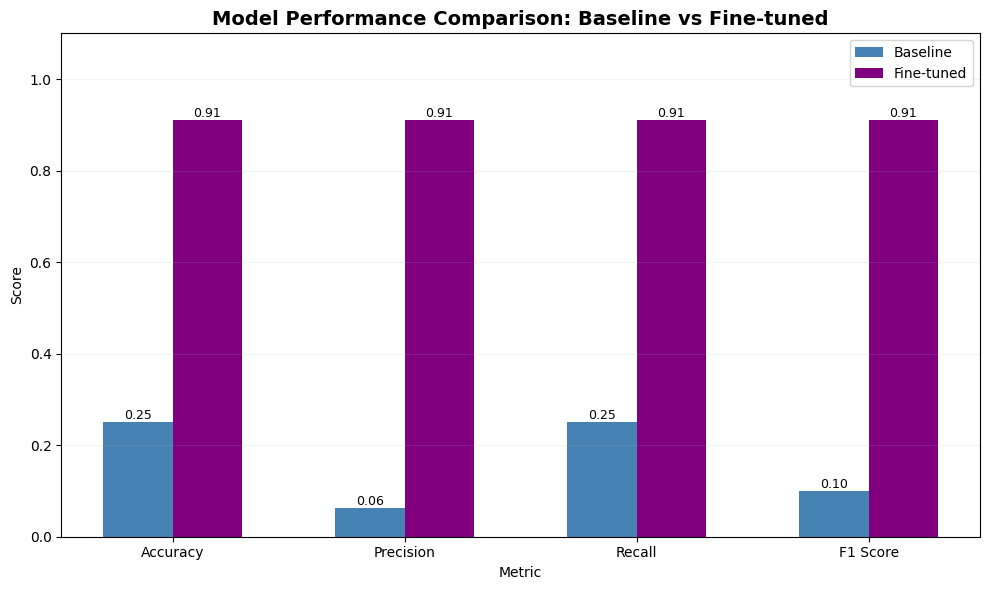

In [25]:

# COMPARISON VISUALISATION


metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
baseline_scores = [baseline_accuracy, baseline_precision, baseline_recall, baseline_f1]
finetuned_scores = [test_acc, test_prec, test_rec, test_f1]

x = np.arange(len(metrics))
width = 0.30

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline', color='steelblue')
bars2 = ax.bar(x + width/2, finetuned_scores, width, label='Fine-tuned', color='purple')

ax.set_xlabel('Metric', fontsize=10)
ax.set_ylabel('Score', fontsize=10)
ax.set_title('Model Performance Comparison: Baseline vs Fine-tuned', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.15)


# Value labels (simple)
for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f'{bar.get_height():.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )
plt.tight_layout()
plt.show()



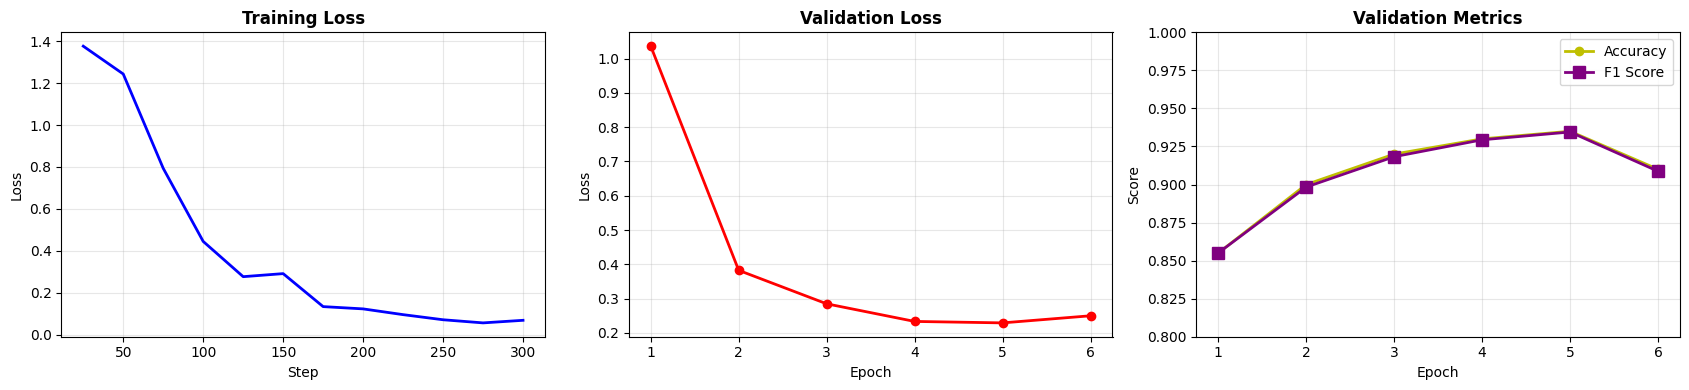


Training Progress:
Epoch    Train Loss   Val Loss     Accuracy     F1          
1        1.2440       1.0366       0.8550       0.8550      
2        0.4447       0.3823       0.9000       0.8983      
3        0.2909       0.2846       0.9200       0.9183      
4        0.1226       0.2332       0.9300       0.9294      
5        0.0707       0.2290       0.9350       0.9345      
6        0.0681       0.2497       0.9100       0.9087      


In [26]:

#TRAINING CURVES

history = trainer.state.log_history


#Extracting training loss
train_losses = [(item["step"], item["loss"])
                for item in history
                if "loss" in item and "eval_loss" not in item]
# extracting evaluation metrics
eval_data = [(item["epoch"], item["eval_loss"], item["eval_accuracy"], item["eval_f1"])
               for item in history
               if "eval_loss" in item]



#  figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# first plot: Training Loss

steps, losses = zip(*train_losses)
axes[0].plot(steps, losses, 'b-', linewidth=2)
axes[0].set_title('Training Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.3)


# second plot: Validation Loss
epochs, eval_losses, accuracies, f1_scores = zip(*eval_data)
axes[1].plot(epochs, eval_losses, 'r-o', linewidth=2)
axes[1].set_title("Validation Loss",fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)


# third plot: Accuracy and F1
axes[2].plot(epochs, accuracies, "y-o", linewidth=2, label='Accuracy')
axes[2].plot(epochs, f1_scores, 'purple', marker='s', linewidth=2, markersize=8, label='F1 Score')
axes[2].set_title('Validation Metrics', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Score')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_ylim(0.8, 1.0)



plt.tight_layout()
plt.show()

# Printing training progress table
print("\nTraining Progress:")

print(f"{'Epoch':<8} {'Train Loss':<12} {'Val Loss':<12} {'Accuracy':<12} {'F1':<12}")
for epoch, val_loss, acc, f1 in eval_data:
    train_loss = [h['loss'] for h in history if 'loss' in h and h.get('epoch', 0) <= epoch][-1] if train_losses else 'N/A'
    print(f"{epoch:<8.0f} {train_loss:<12.4f} {val_loss:<12.4f} {acc:<12.4f} {f1:<12.4f}")



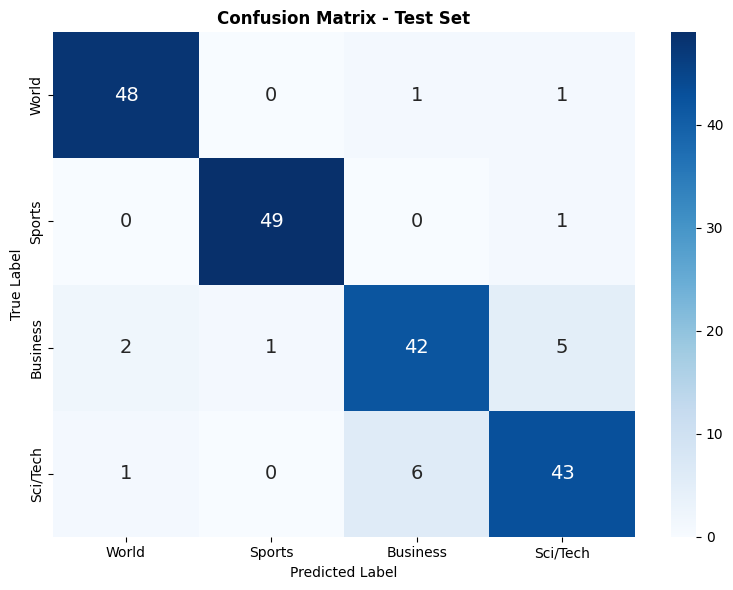


Per-class performance
Class           Correct  Total    Acc     
--------------------------------------------------
World           48       50       96.0%   
Sports          49       50       98.0%   
Business        42       50       84.0%   
Sci/Tech        43       50       86.0%   


In [27]:

# CONFUSION MATRIX

cm = confusion_matrix(labels, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={'size': 14})
plt.title('Confusion Matrix - Test Set', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()



# Per-class accuracy
print("\nPer-class performance")

print(f"{'Class':<15} {'Correct':<8} {'Total':<8} {'Acc':<8}")
print("-" * 50)

for i, name in enumerate(class_names):
    total = cm[i].sum()
    correct = cm[i, i]
    acc = correct / total if total else 0
    print(f"{name:<15} {correct:<8} {total:<8} {acc:<8.1%}")


In [28]:
print("\nMost Common Misclassifications")

print(f"\n\n{'True Label':<15} {'Predicted':<15} {'Count':<8} {'%':<6}")
print("-" * 50)

total_errors = np.sum(preds != labels)

rows = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i][j] > 0:
            count = cm[i][j]
            percentage = (count / total_errors) * 100
            rows.append((class_names[i], class_names[j], count, percentage))

# sort by count (descending)
rows.sort(key=lambda x: x[2], reverse=True)

for true_label, pred_label, count, percentage in rows:
    print(f"{true_label:<15} {pred_label:<15} {count:<8} {percentage:.1f}%")



Most Common Misclassifications


True Label      Predicted       Count    %     
--------------------------------------------------
Sci/Tech        Business        6        33.3%
Business        Sci/Tech        5        27.8%
Business        World           2        11.1%
World           Business        1        5.6%
World           Sci/Tech        1        5.6%
Sports          Sci/Tech        1        5.6%
Business        Sports          1        5.6%
Sci/Tech        World           1        5.6%


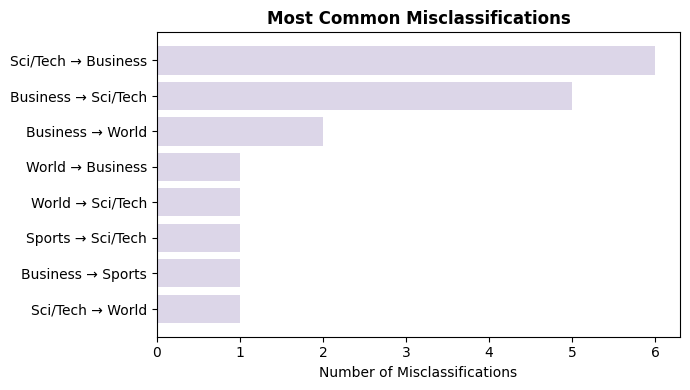

In [29]:
# Misclassification data
new_labels = [
    "Sci/Tech → Business",
    "Business → Sci/Tech",
    "Business → World",
    "World → Business",
    "World → Sci/Tech",
    "Sports → Sci/Tech",
    "Business → Sports",
    "Sci/Tech → World"
]

new_counts = [6, 5, 2, 1, 1, 1, 1, 1]

# Sorting by count (descending)
new_labels, new_counts = zip(*sorted(zip(new_labels, new_counts), key=lambda x: x[1], reverse=True))

# Plot
plt.figure(figsize=(7, 4))
plt.barh(new_labels, new_counts, color="#dcd6e8")
plt.xlabel("Number of Misclassifications")
plt.title("Most Common Misclassifications", fontweight="bold")
plt.gca().invert_yaxis()  # highest on top

plt.tight_layout()
plt.show()


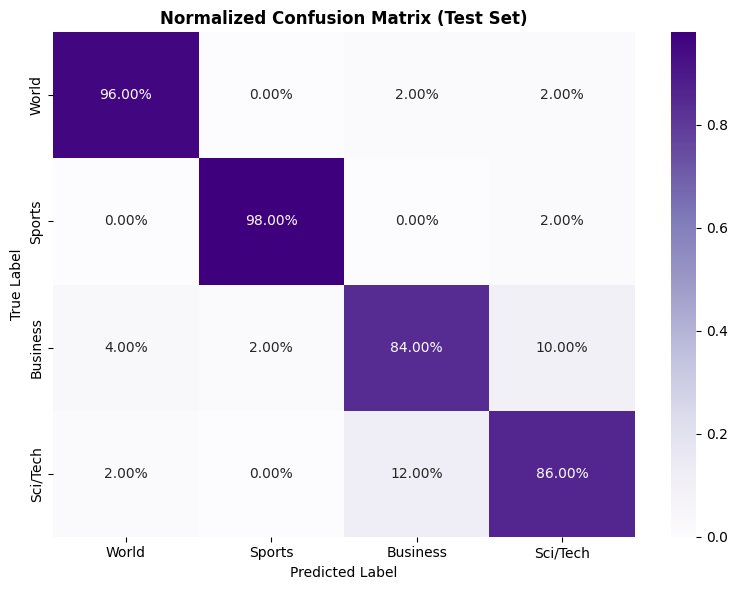

In [30]:
# NORMALIZED CONFUSION MATRIX (by true class)

cm = confusion_matrix(labels, preds)

# normalize by row (true label)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2%',
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix (Test Set)", fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


In [31]:
print("MISCLASSIFIED EXAMPLES")
print( )

# indices where prediction != ground truth
error_idx = np.where(preds != labels)[0] #names misclassified_idx
n_errors = len(error_idx)
n_total = len(labels)

print(f"\nMisclassified: {n_errors}/{n_total} ({100*n_errors/n_total:.1f}%)")
print(f"Correct:       {n_total - n_errors}/{n_total} ({100*(n_total-n_errors)/n_total:.1f}%)")


# analysis of examples
print("\n\nDETAILED ANALYSIS OF MISCLASSIFIED EXAMPLES")
print("="*60)


for k, idx in enumerate(error_idx[:20], start=1):
    true_id = int(labels[idx])
    pred_id = int(preds[idx])

    text = test_sampled["text"][int(idx)]

    print(f"\n\nExample {k}")
    print("─" * 60)
    print(f"Text:            {text[:220]}...")
    print(f"Ground Truth:    {class_names[true_id]}")
    print(f"Predicted Label: {class_names[pred_id]}")

    # commentary based on confusion type
    if (true_id == 2 and pred_id == 3) or (true_id == 3 and pred_id == 2):
        print(f"\nCommentary: Business/Sci-Tech overlap. The article likely discussestechnology companies or any tech-related")
        print(f"        business news,containing vocabulary common to both categories.")
    elif (true_id == 0 and pred_id == 2) or (true_id == 2 and pred_id == 0):
        print(f"\nCommentary: World/Business overlap. This article likely covers international economics or global market")
        print(f"              news, thus blurring the boundary between world affairs and business.")
    elif (true_id == 0 and pred_id == 1) or (true_id == 1 and pred_id == 0):
        print(f"\nCommentary: World/ Sci/Tech overlap. This article likely discusses technology within a global context such")
        print(f"              as international research or innovation policies.")
    elif (true_id == 1 and pred_id == 2) or (true_id == 2 and pred_id == 1):
        print(f"\nCommentary: Sports/Business overlap. This article likely discusses sports business deals, finances of sports  ")
        print(f"              teams, or athlete contracts.")
    else:
        print(f"\nCommentary: Unusual phrasing that does not clearly fit into a single category; making the classification ")
        print(f"              ambiguous for the model.           ")

MISCLASSIFIED EXAMPLES


Misclassified: 18/200 (9.0%)
Correct:       182/200 (91.0%)


DETAILED ANALYSIS OF MISCLASSIFIED EXAMPLES


Example 1
────────────────────────────────────────────────────────────
Text:            SUVs: Live And Let Die NEW YORK - The newly released traffic crash fatality data have something for everyone in the debate about the safety of sport utility vehicles. ...
Ground Truth:    Business
Predicted Label: Sci/Tech

Commentary: Business/Sci-Tech overlap. The article likely discussestechnology companies or any tech-related
        business news,containing vocabulary common to both categories.


Example 2
────────────────────────────────────────────────────────────
Text:            Is this the end of IT as we know it? Halsey Minor, CEO of hosted integration provider grand central Communications, has a powerful message for IT: In four years, ... basically the whole notion of enterprise application s...
Ground Truth:    Business
Predicted Label: Sci/Tech

Commentar

# **8. Interactive Demo**

In [ ]:

#INTERACTIVE DEMO WITH GRADIO
# installing Gradio
!pip install gradio -q
import gradio as gr

label_123 = ["World", "Sports", "Business", "Sci/Tech"]

# Define prediction function
def classify_news(text):
    text = (text or "").strip()
    if not text:
        return {label: 0.0 for label in label_123}
    device = next(model.parameters()).device

    inputs = tokenizer(text,return_tensors="pt", truncation=True, padding=True, max_length=128
    )

    # moving to same device as the model
    inputs = {k: v.to(device) for k, v in inputs.items()}
    model.eval() #or remove


    with torch.no_grad():
        logits = model(**inputs).logits

    probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
    #Return as dictionary for Gradio label
    return {label_123[i]: float(probs[i]) for i in range(len(label_123))}


    #probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()



#  Gradio interface
demo = gr.Interface(
    fn=classify_news,
    inputs=gr.Textbox(
        lines=4,
        placeholder="Enter a news headline or article description...",
        label="News Article Text"
    ),
    outputs=gr.Label(num_top_classes=4,label="Predicted Category"),

    title=" News Article Classifier",
    description="""
    Classifies news articles into four categories:
    **World**, **Sports**, **Business**, and **Sci/Tech**.

    Enter a news headline or article description to view model's prediction with confidence scores.

    *Model: fine-tuned DistilBERT on AG News.*
    """,
    theme=gr.themes.Soft(),
    flagging_mode="never"
)

# Launching the demo
demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://20ce88c62f575b93c6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
